<a href="https://colab.research.google.com/github/Muhammad-alt/DATA201-labs/blob/main/Assignments/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 Homework - Regularization

In [18]:
%pip -q install ISLP

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score



In [20]:
hitters = load_data('Hitters')


In [21]:
#remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy()

#Set your features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']    # thousands of dollars

#define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


## Part 1 - Experimenting with α

In [22]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])

baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])

baseline.fit(X_train, y_train)

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


In [26]:
alpha_values = [0.1, 10, 100]
rows = [] # for my evaluation scores


for kind, estimator in [('Lasso', Lasso(max_iter=30000))]:
    for a in alpha_values:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train) # train the model on training set

        #get the model's coefficients
        coefs = pipe.named_steps['model'].coef_

        #each time the loop runs, we add one dictionary to the list "rows".
        rows.append({
            'Lasso alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))), # predict then evaluate RMSE using training set
            'Testing RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))) # predict then evaluate RMSE using testing set
        })

alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Lasso alpha,Nonzero coefficients,Training RMSE,Testing RMSE
0,0.1,19,289.38,356.83
1,10.0,9,303.10,381.84
2,100.0,5,341.39,395.12


### Questions:

**1. As α increases, what happens to the number of retained predictors?**

For Lasso, as the values increase, the number of retained predictors goes down. If we added higher alpha values, there would be more zero coefficients.  

<br>

**2. Does a smaller number of predictors always lead to a lower test RMSE?**

No. As we can see, the test RMSE goes up for Lasso as the number of coefficients goes down.

## Part 2 - Visualize and interpret

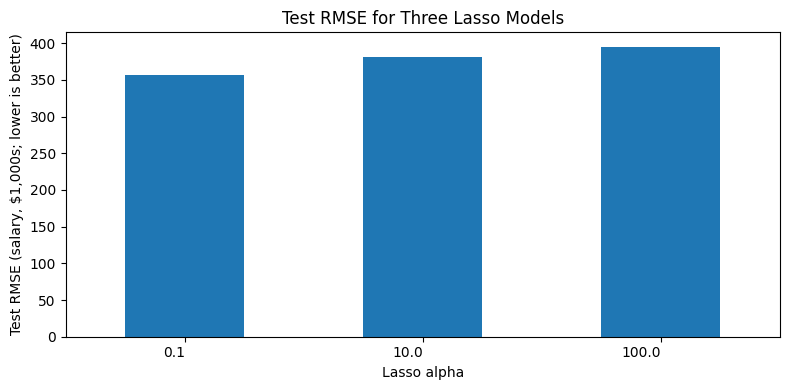

In [50]:
ax = alpha_table.plot(kind='bar', x='Lasso alpha', y='Testing RMSE', legend=False, figsize=(8, 4))
ax.set_ylabel('Test RMSE (salary, $1,000s; lower is better)')
ax.set_title('Test RMSE for Three Lasso Models')
plt.xticks(rotation=0,ha='right')
plt.tight_layout()
plt.show()

### Questions:

**1. Which α produces the lowest test RMSE among the three values?**

The α that produces the lowest test RMSE among the three values is 0.1, with an RMSE of around 350.

<br>

**2. Which α appears to cause the most underfitting? Explain using bias.**

The α that appears to cause the most underfitting is 100. This is because the model is very rigid (bias) as it removes a lot of the coefficients. This way, it does not learn the complexity of the dataset and performs bad on the testing set (as well as the training), causing it to be biased (underfit).

<br>

**3. Why might a model with higher training RMSE produce lower test RMSE?**

A model with a higher training RMSE may produce lower test RMSE because a regularization model pays the price of having more error on the training set to do well on the testing set. It does this by avoiding overfitting: the model avoids this through regularization (in this case, through Lasso).

In essence, when a model overfits on the data (high variance), it has a low training RMSE and high testing RMSE, but the Lasso model avoids overfitting and thereby has higher training RMSE than testing RMSE because it doesn't completely learn the training set (therefore having some training RMSE) and then does better on the testing set (therfore having lower testing RMSE).

## Part 3 - Model Interpretation

In [29]:
feature_names = baseline.named_steps['preprocess'].get_feature_names_out()

lasso_100 = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', Lasso(alpha=100, max_iter=30000))
])

lasso_100.fit(X_train, y_train)

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'OLS': baseline.named_steps['model'].coef_,
    'Lasso (alpha=100)': lasso_100.named_steps['model'].coef_
})

display(coef_table.round(2))

,Feature,OLS,Lasso (alpha=100)
0,num__AtBat,-252.65,0.00
1,num__Hits,379.23,76.59
2,num__HmRun,64.67,0.00
3,num__Runs,-82.33,0.00
4,num__RBI,-52.67,0.00
5,num__Walks,113.43,16.17
6,num__Years,35.91,0.00
7,num__CAtBat,-318.63,0.00
8,num__CHits,-136.22,0.00
9,num__CHmRun,-50.89,0.00


### Questions

**1. Identify two predictors that Lasso sets to zero at α = 100.**

Lasso set cat_newLeague_N and num_Assists to zero.

<br>

**2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary? Explain.**

Setting coefficients to zero through Lasso does not prove that those predictors have no relationship. This is because Lasso may reduce a coefficient to zero due to it being correlated with other predictors. It does not mean that the predictor has no relationship with salary.

<br>

**3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance**

I would prefer the simpler model that uses fewer predictors because a model that is simpler takes less time and power. A data scientist's job isn't just to create the best model, it's to create the most parsimonious model that uses the least amount of company GPU and time, while ensuring it gets the job done.


## Part 4 - Choosing the Right Regression Model

**Scenario A: A researcher has data from 80 patients with 200 medical measurements. The
goal is to identify a small number of measurements that may be useful for predicting
disease severity.**


The best regression model would be a Lasso linear regression because the researcher wants to identify a small number of measurements that may be useful for predicting disease severity. For this goal, it is best to cut down the 200 medical measurements into a manageable amount, and this is possible through Lasso. Ridge does not cut down coefficients/variables, and ordinary linear regression has no regularization.


<br>




**Scenario B: A company wants to predict employee salaries using 40 predictors. Many
predictors are strongly correlated, and the company believes most contain useful
information. Keeping all predictors is not a concern.**


The best model would be a Ridge linear regression because we know many predictors are strongly correlated and may provide useful information, so cutting them out with Lasso—which usually eliminates variables if they're highly correlated—would be disadvantageous. Furthermore, keeping all predictors isn't a concern, and Ridge keeps all predictors. Since predictors are still highly correlated, tuning them down with Ridge may prove beneficial to predicting employee salaries. Ordinary linear regression doesn't regularize the correlated variables, so if that's the goal, then OLR may work too.


<br>




**Scenario C: A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is
easy to interpret.**


The best regression model would be Ordinary linear regression because the researcher wants a simple model, and OLR is the simplest out of the three. However, if some of the predictors are correlated and cutting them out would prove beneficial, and overfitting is an issue, then Lasso may work best. If cutting them out wouldn't prove beneficial but they're still a concern, and overfitting is an issue, then Ridge may work best. Otherwise, given the information, OLR would work the best.  


<br>




**Scenario D: A company has 500 observations and 25 predictors. It is unclear how many
predictors are useful or how strongly they are correlated. The company wants the most
accurate predictions possible.**


Choosing the best regression model would mean tuning various hyperparameters given the information. This is where cross-validation comes in handy because we don't want to look at the testing dataset when we're choosing the hyperparameters.


Given that, I believe the best model would be Ridge linear regression because using Lasso to cut out useful predictors (after learning they're useful through cross-validation) may be disadvantageous, and using ordinary linear regression when there's highly correlated variables (after cross-validation) may produce inaccurate predictions.  
